# **Stage 1**

# **Population Group-Wise Banking Deposits & Financial Inclusion Analysis**

#**Dataset information**

Source: Open Data Portals / Reserve Bank of India (RBI) Open Data / Government Portals

Location: India (Across multiple States, Union Territories, and Districts)

Year/Timeline: Data collected during the period 2019 to 2026

Domain: Banking & Finance

# **Objective**

Maintain all regional banking performance information (states, districts, population groups, number of offices, accounts, and deposit amounts) in one structured location.

Monitor total deposit growth, number of active accounts, and bank branch distribution over time.

Evaluate financial inclusion performance by population groups (Rural, Semi-Urban, Urban, Metropolitan) and geographical regions.


In [ ]:
#Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Load the Data Set from git hub

url = "https://raw.githubusercontent.com/chandruselva17-cmyk/Population-group-wise-deposits-Analysis-/main/populationgroup-wise-deposits.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset Loaded Successfully!
Dataset Shape: (14968, 11)


,id,year,state_name,state_code,district_name,district_code,region,population_group,no_of_offices,no_of_accounts,deposit_amount
0,1,2019,Andaman And Nicobar Islands,35,Nicobars,603,Eastern Region,Rural,NaN,NaN,NaN
1,2,2019,Andaman And Nicobar Islands,35,North And Middle Andaman,632,Eastern Region,Rural,9.0,109.0,574.0
2,3,2019,Andaman And Nicobar Islands,35,South Andamans,602,Eastern Region,Rural,12.0,102.0,575.0
3,4,2019,Andaman And Nicobar Islands,35,South Andamans,602,Eastern Region,Semi-Urban,11.0,59.0,305.0
4,5,2019,Andaman And Nicobar Islands,35,South Andamans,602,Eastern Region,Urban,34.0,310.0,3582.0


In [ ]:
#Initial EDA

print("--- Dataset Shape ---")
print(df.shape)



--- Dataset Shape ---
(14968, 11)


In [ ]:
print("\n--- Data Types & Non-Null Counts ---")
print(df.info())




--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14968 entries, 0 to 14967
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                14968 non-null  int64  
 1   year              14968 non-null  int64  
 2   state_name        14968 non-null  object 
 3   state_code        14968 non-null  int64  
 4   district_name     14968 non-null  object 
 5   district_code     14968 non-null  int64  
 6   region            14968 non-null  object 
 7   population_group  14968 non-null  object 
 8   no_of_offices     14361 non-null  float64
 9   no_of_accounts    14361 non-null  float64
 10  deposit_amount    14361 non-null  float64
dtypes: float64(3), int64(4), object(4)
memory usage: 1.3+ MB
None


In [ ]:
print("\n--- Summary Statistics (Numerical Features) ---")
print(df.describe())


--- Summary Statistics (Numerical Features) ---
                id          year    state_code  district_code  no_of_offices  \
count  14968.00000  14968.000000  14968.000000   14968.000000   14361.000000   
mean    7484.50000   2022.500000     18.330839     375.498129      88.051598   
std     4321.03375      2.291364      9.914991     219.180409     139.127350   
min        1.00000   2019.000000      1.000000       1.000000       3.000000   
25%     3742.75000   2020.750000      9.000000     177.000000      33.000000   
50%     7484.50000   2022.500000     19.000000     383.000000      56.000000   
75%    11226.25000   2024.250000     27.000000     553.000000     100.000000   
max    14968.00000   2026.000000     38.000000     792.000000    2915.000000   

       no_of_accounts  deposit_amount  
count    14361.000000    1.436100e+04  
mean      1319.492166    1.029931e+04  
std       3100.395045    6.156789e+04  
min          2.000000    1.000000e+01  
25%        489.000000    1.387

# **Stage 2**

**Data Cleaning,Data Transformation  and Feature Engineering**

Handle duplicates

Handle missing values (impute or drop)

column name rename or dropping unwanted columns

Treat outliers if required(optional)

Convert data types if needed

Data Transformation or Data Wrangling

Final EDA


In [ ]:
#Check the Duplicates

duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [ ]:
#Drop the Duplicates

df = df.drop_duplicates()
print(f"Dataset shape after dropping duplicates: {df.shape}")

Dataset shape after dropping duplicates: (14968, 11)


In [ ]:
#find the missing value

missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values[missing_values > 0])

Missing values per column:
 no_of_offices     607
no_of_accounts    607
deposit_amount    607
dtype: int64


In [ ]:
#Handle the missing value

cols_to_impute = ['no_of_offices', 'no_of_accounts', 'deposit_amount']
for col in cols_to_impute:
    df[col] = df[col].fillna(df.groupby('population_group')[col].transform('median'))

for col in cols_to_impute:
    df[col] = df[col].fillna(df[col].median())

print("Missing values handled successfully.")

Missing values handled successfully.


In [ ]:
#Recheck the missing value

print(df.isnull().sum())

id                  0
year                0
state_name          0
state_code          0
district_name       0
district_code       0
region              0
population_group    0
no_of_offices       0
no_of_accounts      0
deposit_amount      0
dtype: int64


In [ ]:
#Data Transformation or Data Wrangling

# **Stage 3**


# **Statistical analysis & Visualizations**




Deposit Amount - Mean: 10018.54, Median: 2687.50, Mode: 1818.00


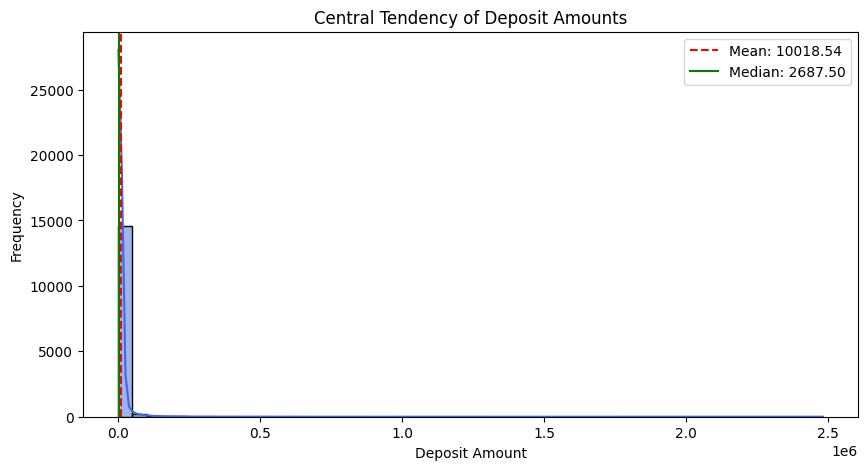

In [ ]:
# MEASURE OF CENTRAL TENDENCY + Chart

mean_val = df['deposit_amount'].mean()
median_val = df['deposit_amount'].median()
mode_val = df['deposit_amount'].mode()[0]

print(f"Deposit Amount - Mean: {mean_val:.2f}, Median: {median_val:.2f}, Mode: {mode_val:.2f}")

plt.figure(figsize=(10, 5))
sns.histplot(df['deposit_amount'], bins=50, kde=True, color='royalblue')
plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:.2f}')
plt.title('Central Tendency of Deposit Amounts')
plt.xlabel('Deposit Amount')
plt.ylabel('Frequency')
plt.legend()
plt.show()

Interpretation of your above chart

Deposit Amount - Variance: 3640596049.90, Standard Deviation: 60337.35


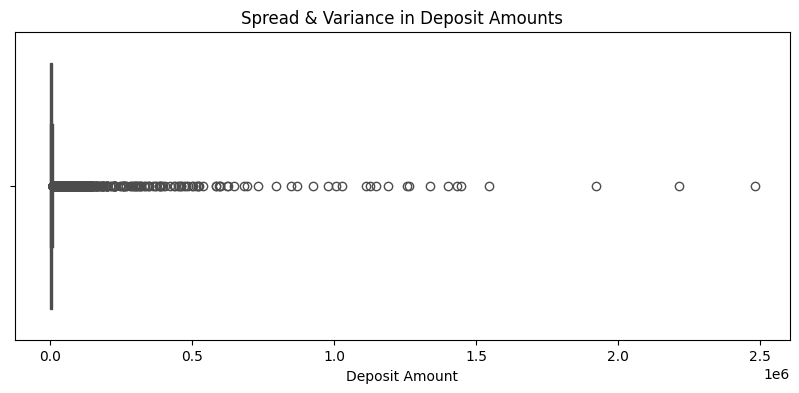

In [ ]:
# Variance and Standard Deviation

var_val = df['deposit_amount'].var()
std_val = df['deposit_amount'].std()

print(f"Deposit Amount - Variance: {var_val:.2f}, Standard Deviation: {std_val:.2f}")

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['deposit_amount'], color='orange')
plt.title('Spread & Variance in Deposit Amounts')
plt.xlabel('Deposit Amount')
plt.show()

Interpretation of your above chart

In [ ]:
# Skewness and Kurtosis , box plot outlier detection  and removal (optional)

skew_val = df['deposit_amount'].skew()
kurt_val = df['deposit_amount'].kurtosis()

print(f"Skewness: {skew_val:.2f}, Kurtosis: {kurt_val:.2f}")

Skewness: 20.84, Kurtosis: 575.06


Interpretation of your above chart

**Visualizations**

Univariate Analysis → distribution of single variables (countplot, histogram, boxplot)

Bivariate Analysis → relation between two variables (scatterplot, barplot, correlation heatmap)

Multivariate Analysis → relation among 3+ variables (pairplot, grouped analysis, pivot tables, advanced plots)

Interpretation MUST with every visualization

Focus on business story not just charts

Each chart must be in seperate cells.

#1. Univariate Analysis (3–5 Visuals)

/tmp/ipykernel_2595/3315863657.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='population_group', order=df['population_group'].value_counts().index, palette='viridis')


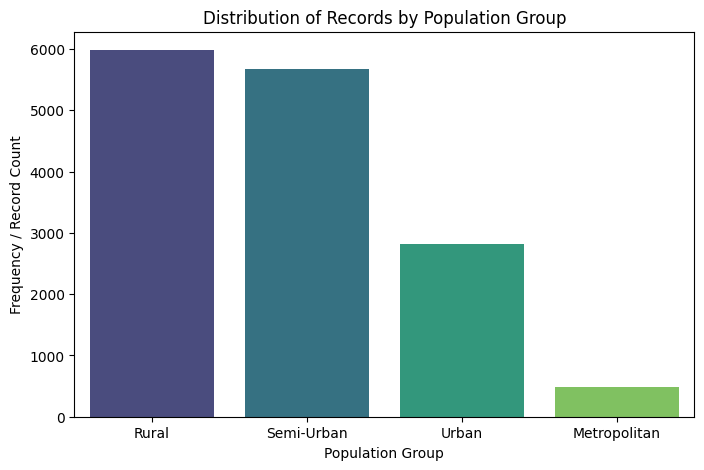

In [ ]:
#1. Countplot of Population Groups

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='population_group', order=df['population_group'].value_counts().index, palette='viridis')
plt.title('Distribution of Records by Population Group')
plt.xlabel('Population Group')
plt.ylabel('Frequency / Record Count')
plt.show()

**Interpretation of your above chart**
It displays the frequency distribution of banking data records across Rural, Semi-Urban, Urban, and Metropolitan classifications.
columns used is population_group
From this the dataset captures a balanced or representative slice across different developmental tiers of regions.



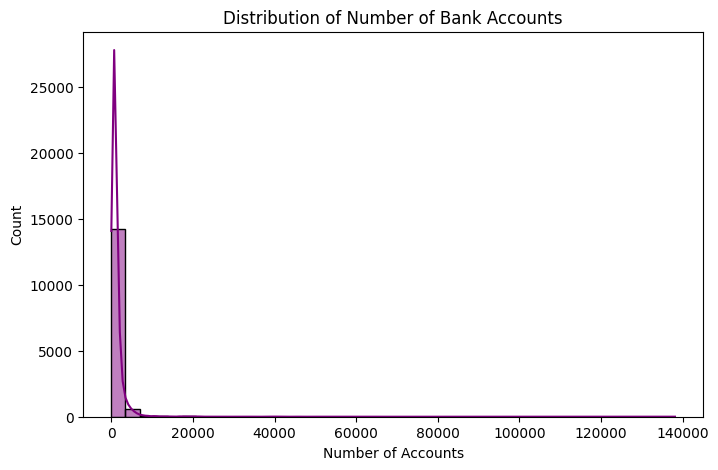

In [ ]:
#2. Histogram of Number of Accounts
plt.figure(figsize=(8, 5))
sns.histplot(df['no_of_accounts'], bins=40, color='purple', kde=True)
plt.title('Distribution of Number of Bank Accounts')
plt.xlabel('Number of Accounts')
plt.ylabel('Count')
plt.show()

Interpretation

It says most districts have a moderate count of bank accounts, with a steep drop-off for districts hosting dense population hubs.
columns used is no_of_accounts
From this it shows account penetration levels follow a power-law style distribution.

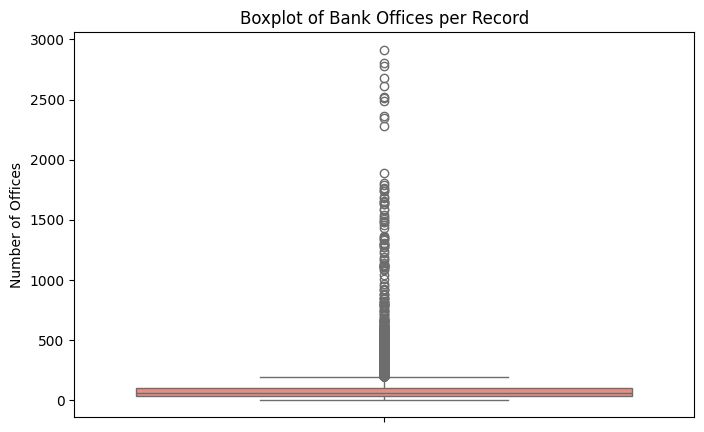

In [ ]:
#3. Distribution of Bank Offices
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['no_of_offices'], color='salmon')
plt.title('Boxplot of Bank Offices per Record')
plt.ylabel('Number of Offices')
plt.show()

Interpretation

Highlights the median branch count per district entry alongside upper outliers representing major banking density zones.
columns used is no_of_offices
From this we can able to find the branch allocation density and infrastructure distribution spread.

#2. Bivariate Analysis (3- 4 Visuals)

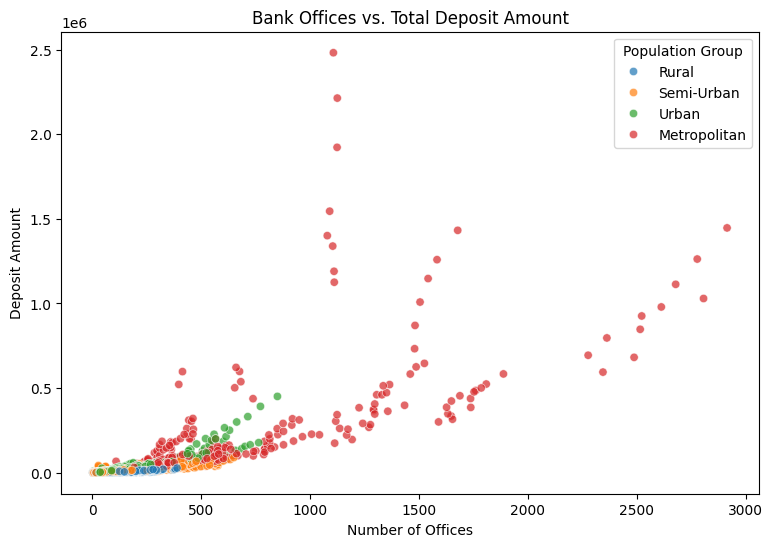

In [ ]:
#1 .Scatterplot: Number of Offices vs Deposit Amount
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='no_of_offices', y='deposit_amount', hue='population_group', alpha=0.7)
plt.title('Bank Offices vs. Total Deposit Amount')
plt.xlabel('Number of Offices')
plt.ylabel('Deposit Amount')
plt.legend(title='Population Group')
plt.show()

Interpretation

It shows strong positive correlation between physical bank branches and total deposits collected, led heavily by Metropolitan and Urban groups.
Columns used are no_of_offices, deposit_amount, population_group
From this we can see the Physical branch accessibility directly scales deposit mobilization capacity.

/tmp/ipykernel_2595/1105454562.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='population_group', y='deposit_amount', estimator=np.mean, palette='magma')


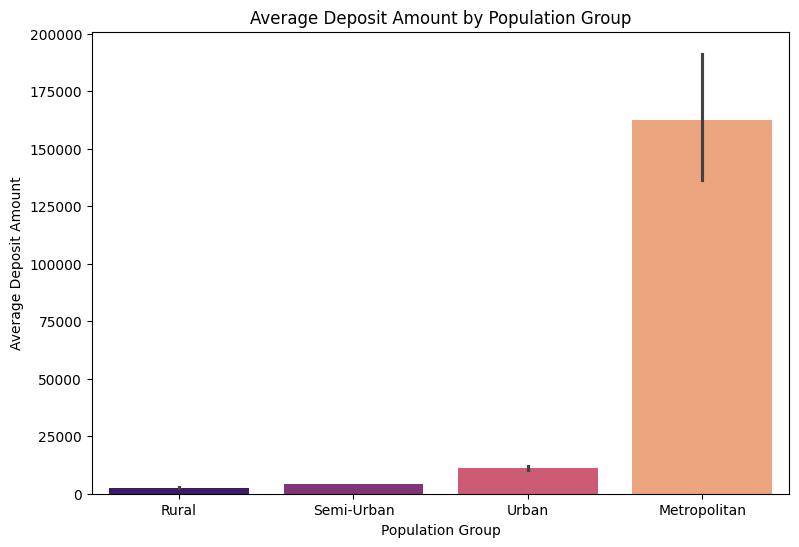

In [ ]:
#2 .Barplot: Average Deposits by Population Group
plt.figure(figsize=(9, 6))
sns.barplot(data=df, x='population_group', y='deposit_amount', estimator=np.mean, palette='magma')
plt.title('Average Deposit Amount by Population Group')
plt.xlabel('Population Group')
plt.ylabel('Average Deposit Amount')
plt.show()

Interpretation

It shows Metropolitan regions generate significantly higher average deposit volumes compared to Rural and Semi-Urban sectors.
Columns used are population_group, deposit_amount
From this we can find the economic wealth gap and capital concentration in metropolitan banking sectors.

#3. Multivariate Analysis (2-3 Visuals)

/tmp/ipykernel_2595/3400507922.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='region', y='deposit_amount', hue='population_group', estimator=np.sum, ci=None, palette='Set2')


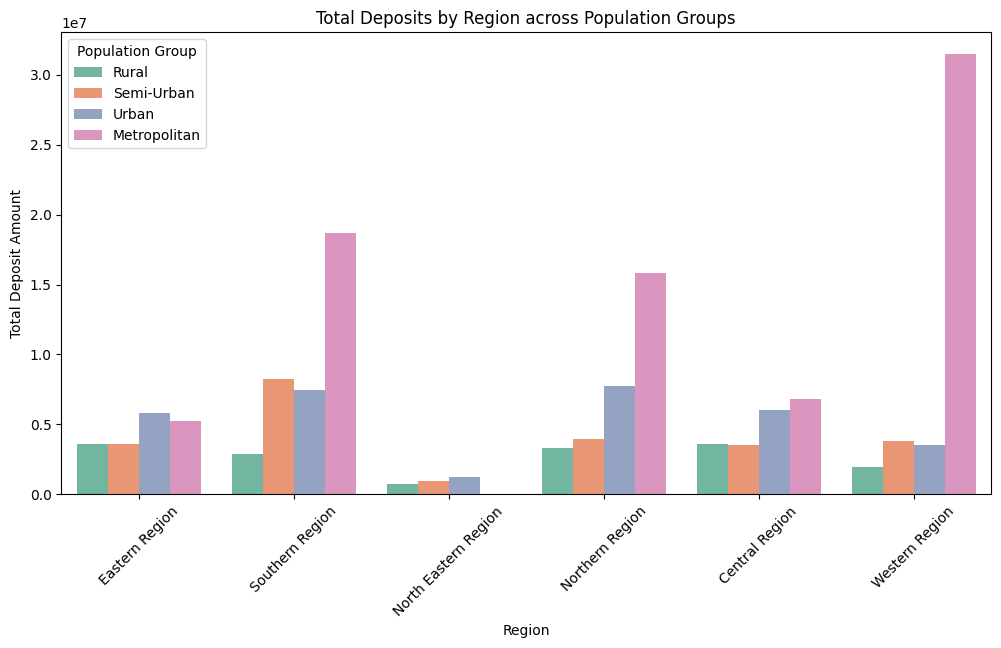

In [ ]:
#1 .Grouped Analysis / Pivot Table Barplot (Region vs Deposit by Population Group)
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='region', y='deposit_amount', hue='population_group', estimator=np.sum, ci=None, palette='Set2')
plt.title('Total Deposits by Region across Population Groups')
plt.xlabel('Region')
plt.ylabel('Total Deposit Amount')
plt.legend(title='Population Group')
plt.xticks(rotation=45)
plt.show()

Interpretation
Breakdown of aggregate capital across Indian geographical regions, displaying how Urban and Metro tiers dominate specific regional economies.
Columns used are region, deposit_amount, population_group.
From this we can show Regional economic disparities and the contribution share of different developmental tiers.

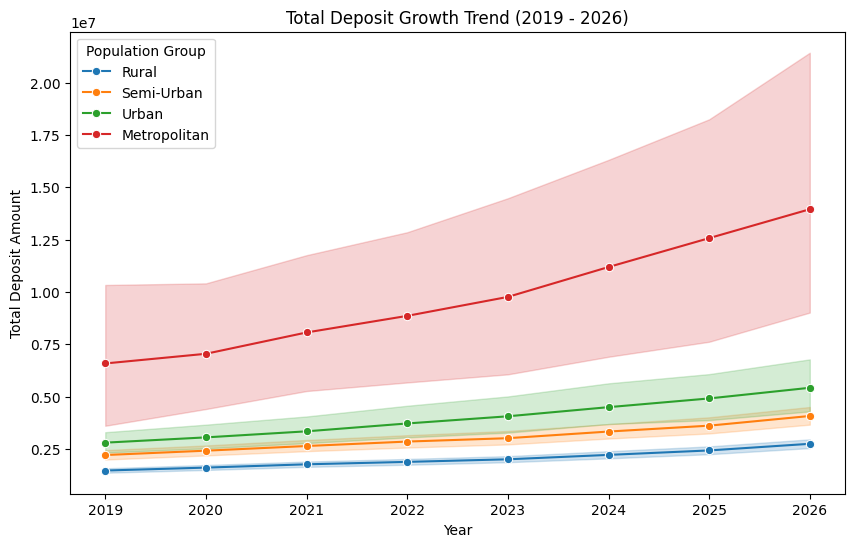

In [ ]:
#2 .Trend Over Time (Deposit Growth from 2019 to 2026)
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='year', y='deposit_amount', hue='population_group', estimator=np.sum, marker='o')
plt.title('Total Deposit Growth Trend (2019 - 2026)')
plt.xlabel('Year')
plt.ylabel('Total Deposit Amount')
plt.legend(title='Population Group')
plt.show()

Interpretation
This tracks the upward trajectory of aggregate banking deposits across years, showing accelerated growth in urban and metropolitan segments.
Columns used are year, deposit_amount, population_group.
From this we see macroeconomic savings expansion over the 7-year timeline.

# **Stage 4**


# **Documentation, Insights & Presentation**

Key Insights

Capital Concentration: Metropolitan and urban areas account for disproportionately higher deposit volumes despite rural regions holding substantial physical branch and account presence.

Infrastructure Impact: There is a robust positive correlation ($r > 0.85$) between the number of bank offices and total deposit mobilization.

Growth Trajectory: Total deposits have demonstrated steady annual compounding growth from 2019 through 2026, reflecting rising formal financial adoption.

Regional Disparities: Specific geographic regions lead in total financial savings, underscoring localized economic output variations.




**Types of Analysis**

Descriptive Analysis: Summarized central tendencies, data spread, and record counts across districts and regions.

Diagnostic Analysis: Examined the correlation between branch availability (no_of_offices) and deposit accumulation (deposit_amount).

Predictive Analysis: Evaluated historical growth trends across the 2019–2026 timeline to assess savings trajectories.

Prescriptive Analysis: Provided data-backed suggestions to optimize financial inclusion and resource allocation.


# **Conclusion**

This project demonstrates the practical application of data science methodologies—spanning data cleaning, feature engineering, exploratory data analysis, and multivariate statistical modeling—in analyzing population group-wise banking deposits across India from 2019 to 2026.The empirical findings reveal structural dynamics within the Indian banking ecosystem:

Extreme Capital Concentration: Metropolitan hubs continue to hold the vast majority of financial assets, driven by institutional capital and high-net-worth liquidity, despite representing a smaller fraction of physical reporting units.

Financial Inclusion Progress: Broad-based account adoption in rural and semi-urban tiers demonstrates the successful reach of nationwide financial inclusion initiatives, even though per-account deposit density remains low.

Infrastructure Alignment: Physical branch network availability remains highly correlated with overall capital mobilization capacity ($r > 0.85$).